In [1]:
# ============================================================
# SECTION 6 — GEMMA 3 VISION SETUP
# ============================================================

!pip -q install -U google-genai

# ============================================================
# SECTION 1 — PROJECT SETUP
# ============================================================


In [2]:

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import sys
import json

# ------------------------------------------------------------
# Project root
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/NITT/Sem 5/PWPI/Multimodal_EEG_EMG_VLM_Project"
)

CODE_DIR = PROJECT_ROOT / "03_Code"
VISION_CODE_DIR = CODE_DIR / "Vision"

NOTEBOOK_DIR = PROJECT_ROOT / "02_Notebooks" / "Vision"

# Add project code directories to Python path
if str(CODE_DIR) not in sys.path:
    sys.path.append(str(CODE_DIR))

if str(VISION_CODE_DIR) not in sys.path:
    sys.path.append(str(VISION_CODE_DIR))

# Create directories if they do not exist
VISION_CODE_DIR.mkdir(parents=True, exist_ok=True)
NOTEBOOK_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:")
print(PROJECT_ROOT)

print("\nDirectory check:")
print(f"03_Code exists: {CODE_DIR.exists()}")
print(f"Vision code directory: {VISION_CODE_DIR}")
print(f"Vision notebook directory: {NOTEBOOK_DIR}")

print("\nPython paths added:")
print(CODE_DIR)
print(VISION_CODE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project root:
/content/drive/MyDrive/NITT/Sem 5/PWPI/Multimodal_EEG_EMG_VLM_Project

Directory check:
03_Code exists: True
Vision code directory: /content/drive/MyDrive/NITT/Sem 5/PWPI/Multimodal_EEG_EMG_VLM_Project/03_Code/Vision
Vision notebook directory: /content/drive/MyDrive/NITT/Sem 5/PWPI/Multimodal_EEG_EMG_VLM_Project/02_Notebooks/Vision

Python paths added:
/content/drive/MyDrive/NITT/Sem 5/PWPI/Multimodal_EEG_EMG_VLM_Project/03_Code
/content/drive/MyDrive/NITT/Sem 5/PWPI/Multimodal_EEG_EMG_VLM_Project/03_Code/Vision


# ============================================================
# SECTION 2 — HANDS23 DATASET INSPECTION
# ============================================================


In [3]:
# ============================================================
# SECTION 2 — HANDS23 DATASET PAIRS
# ============================================================

from pathlib import Path

HANDS23_DIR = PROJECT_ROOT / "01_Data" / "Image" / "hands23"
JPG_DIR = HANDS23_DIR / "jpg"
TXT_DIR = HANDS23_DIR / "txt"

jpg_files = sorted(JPG_DIR.glob("*.jpg"))
txt_files = sorted(TXT_DIR.glob("*.txt"))

# Annotation naming convention:
# image.jpg -> image.jpg.txt

pairs = []

for image_path in jpg_files:
    annotation_path = TXT_DIR / f"{image_path.name}.txt"

    if annotation_path.exists():
        pairs.append({
            "image_path": image_path,
            "annotation_path": annotation_path
        })

print(f"Images found: {len(jpg_files)}")
print(f"Annotations found: {len(txt_files)}")
print(f"Valid image-annotation pairs: {len(pairs)}")
print(f"Images without annotation: {len(jpg_files) - len(pairs)}")
print(f"Orphan annotations: {len(txt_files) - len(pairs)}")

Images found: 26
Annotations found: 28
Valid image-annotation pairs: 26
Images without annotation: 0
Orphan annotations: 2


# ------------------------------------------------------------
# Count image and annotation files
# ------------------------------------------------------------


In [4]:
jpg_files = sorted(JPG_DIR.glob("*.jpg"))
txt_files = sorted(TXT_DIR.glob("*.txt"))

print(f"Number of JPG files: {len(jpg_files)}")
print(f"Number of TXT files: {len(txt_files)}")

Number of JPG files: 26
Number of TXT files: 28


# ============================================================
# SECTION 3 — ANNOTATION FORMAT INSPECTION
# ============================================================

In [5]:
# ============================================================
# SECTION 3 — HANDS23 ANNOTATION PARSER
# ============================================================

def parse_hands23_annotation(txt_path):
    """
    Parse a Hands23 annotation file line-by-line.

    Each non-empty line represents one annotated hand instance.
    Fields are preserved as raw strings for now.
    """

    with open(txt_path, "r", encoding="utf-8") as f:
        lines = [line.strip() for line in f.readlines() if line.strip()]

    annotations = []

    for line in lines:
        fields = [field.strip() for field in line.split("|")]

        annotations.append({
            "raw": line,
            "fields": fields,
            "num_fields": len(fields)
        })

    return annotations

# Find an annotation containing more than one line
multi_hand_example = None

for pair in pairs:
    parsed = parse_hands23_annotation(pair["annotation_path"])

    if len(parsed) > 1:
        multi_hand_example = pair
        break

print("Image:", multi_hand_example["image_path"].name)
print("Annotation:", multi_hand_example["annotation_path"].name)

parsed = parse_hands23_annotation(
    multi_hand_example["annotation_path"]
)

print(f"\nNumber of hand instances: {len(parsed)}")

for i, hand in enumerate(parsed):
    print(f"\nHand instance {i + 1}")
    for j, field in enumerate(hand["fields"], start=1):
        print(f"  Field {j}: {field}")

Image: AR__4R6QekTdrw_9_2070_15.jpg
Annotation: AR__4R6QekTdrw_9_2070_15.jpg.txt

Number of hand instances: 2

Hand instance 1
  Field 1: right_hand
  Field 2: no_contact
  Field 3: 310.706439, 318.336977, 336.929685, 344.655738
  Field 4: None
  Field 5: None
  Field 6: None
  Field 7: None

Hand instance 2
  Field 1: right_hand
  Field 2: inconclusive
  Field 3: 407.244800, 373.413600, 423.731200, 389.901600
  Field 4: None
  Field 5: None
  Field 6: None
  Field 7: None


# ============================================================
# SECTION 4 — HANDS23 DATASET INDEX
# ============================================================

In [6]:


dataset_index = []

for pair in pairs:
    annotations = parse_hands23_annotation(
        pair["annotation_path"]
    )

    dataset_index.append({
        "image_name": pair["image_path"].name,
        "image_path": str(pair["image_path"]),
        "annotation_path": str(pair["annotation_path"]),
        "num_hands": len(annotations),
        "annotations": annotations
    })

print(f"Dataset index entries: {len(dataset_index)}")

print("\nFirst entry:")
print(json.dumps(dataset_index[0], indent=2))

Dataset index entries: 26

First entry:
{
  "image_name": "AR__4R6QekTdrw_9_2070_15.jpg",
  "image_path": "/content/drive/MyDrive/NITT/Sem 5/PWPI/Multimodal_EEG_EMG_VLM_Project/01_Data/Image/hands23/jpg/AR__4R6QekTdrw_9_2070_15.jpg",
  "annotation_path": "/content/drive/MyDrive/NITT/Sem 5/PWPI/Multimodal_EEG_EMG_VLM_Project/01_Data/Image/hands23/txt/AR__4R6QekTdrw_9_2070_15.jpg.txt",
  "num_hands": 2,
  "annotations": [
    {
      "raw": "right_hand | no_contact | 310.706439, 318.336977, 336.929685, 344.655738 | None | None | None | None",
      "fields": [
        "right_hand",
        "no_contact",
        "310.706439, 318.336977, 336.929685, 344.655738",
        "None",
        "None",
        "None",
        "None"
      ],
      "num_fields": 7
    },
    {
      "raw": "right_hand | inconclusive | 407.244800, 373.413600, 423.731200, 389.901600 | None | None | None | None",
      "fields": [
        "right_hand",
        "inconclusive",
        "407.244800, 373.413600, 423.731200

# ============================================================
# SECTION 5 — ANNOTATION VOCABULARY INSPECTION
# ============================================================


In [7]:

from collections import Counter

field_values = {
    "field_1": Counter(),
    "field_2": Counter(),
    "field_5": Counter(),
    "field_6": Counter(),
    "field_7": Counter(),
}

for entry in dataset_index:
    for annotation in entry["annotations"]:

        fields = annotation["fields"]

        if len(fields) >= 1:
            field_values["field_1"][fields[0]] += 1

        if len(fields) >= 2:
            field_values["field_2"][fields[1]] += 1

        if len(fields) >= 5:
            field_values["field_5"][fields[4]] += 1

        if len(fields) >= 6:
            field_values["field_6"][fields[5]] += 1

        if len(fields) >= 7:
            field_values["field_7"][fields[6]] += 1


for field, counter in field_values.items():
    print(f"\n{field}:")
    for value, count in counter.items():
        print(f"  {value!r}: {count}")


field_1:
  'right_hand': 22
  'left_hand': 14

field_2:
  'no_contact': 2
  'inconclusive': 2
  'object_contact': 32

field_5:
  'None': 5
  'neither_,_held': 23
  'neither_,_touched': 1
  'container_,_touched': 1
  'container_,_held': 6

field_6:
  'None': 36

field_7:
  'None': 32
  'Pow-Pris': 4


In [8]:
# ============================================================
# SECTION 7 — GEMINI CLIENT
# ============================================================

from google.colab import userdata
from google import genai

GEMINI_API_KEY = userdata.get("API_KEY")

if not GEMINI_API_KEY:
    raise ValueError(
        "GEMINI_API_KEY not found in Colab Secrets."
    )

gemma_client = genai.Client(api_key=GEMINI_API_KEY)

# Vision-capable Gemini model
# VISION_MODEL = "gemma-3-4b-it"
VISION_MODEL = "gemini-3.1-flash-lite"

print("Gemma vision client initialized.")
print("Model:", VISION_MODEL)

Gemma vision client initialized.
Model: gemini-3.1-flash-lite


# ============================================================
# SECTION 8 — VISION OUTPUT SCHEMA
# ============================================================

In [9]:


VISION_SCHEMA = {
    "type": "OBJECT",
    "properties": {
        "hands": {
            "type": "ARRAY",
            "items": {
                "type": "OBJECT",
                "properties": {
                    "handedness": {
                        "type": "STRING",
                        "description": "left, right, or unknown"
                    },
                    "contact_state": {
                        "type": "STRING",
                        "description": (
                            "no_contact, object_contact, "
                            "inconclusive, or unknown"
                        )
                    },
                    "primary_object": {
                        "type": "STRING",
                        "description": (
                            "Main object associated with the hand, "
                            "or unknown if not identifiable."
                        )
                    },
                    "hand_object_relation": {
                        "type": "STRING",
                        "description": (
                            "held, touched, near, or unknown"
                        )
                    },
                    "grasp_type": {
                        "type": "STRING",
                        "description": (
                            "Observed grasp type if visually inferable; "
                            "otherwise unknown."
                        )
                    }
                },
                "required": [
                    "handedness",
                    "contact_state",
                    "primary_object",
                    "hand_object_relation",
                    "grasp_type"
                ]
            }
        }
    },
    "required": ["hands"]
}

print("Vision schema created.")

Vision schema created.


# ============================================================
# SECTION 9 — GEMMA 3 VISION PROMPT
# ============================================================


In [10]:
# ============================================================
# SECTION 17 — REFINED VISION PROMPT
# ============================================================

VISION_PROMPT = """
You are the vision perception component of a multimodal
EEG + EMG + Image + Text system.

Analyze ONLY the provided image.

Your task is to describe the currently visible hand-object
interaction in a structured way.

For every visibly distinguishable hand that appears relevant:

1. HANDEDNESS
   - left
   - right
   - unknown

2. CONTACT STATE
   - no_contact
   - object_contact
   - inconclusive
   - unknown

3. PRIMARY OBJECT
   Identify the main object that the hand is interacting with.
   Use a short, visually supported object name.
   If no object can be identified, return "unknown".

4. HAND-OBJECT RELATION
   - held
   - touched
   - near
   - unknown

5. GRASP TYPE
   Describe the visually apparent grasp only when there is
   sufficient visual evidence.
   Otherwise return "unknown".

IMPORTANT RULES:

- Count only hands that are actually visible.
- Do not invent or assume a second hand.
- Do not infer hidden hands.
- Do not use information from external annotations.
- Do not invent an object.
- Do not infer human intention from the image.
- Do not infer temporal information from a single image.
- "held" means the object appears to be held in the current
  image; it does NOT prove when the object was picked up.
- If visual evidence is insufficient, use "unknown".
- Return one entry per visually distinguishable hand.
"""

# ============================================================
# SECTION 10 — SELECT TEST IMAGE
# ============================================================

In [11]:


test_entry = dataset_index[0]

test_image_path = Path(test_entry["image_path"])

print("Test image:")
print(test_image_path)

print("\nAnnotation:")
for ann in test_entry["annotations"]:
    print(ann["raw"])

Test image:
/content/drive/MyDrive/NITT/Sem 5/PWPI/Multimodal_EEG_EMG_VLM_Project/01_Data/Image/hands23/jpg/AR__4R6QekTdrw_9_2070_15.jpg

Annotation:
right_hand | no_contact | 310.706439, 318.336977, 336.929685, 344.655738 | None | None | None | None
right_hand | inconclusive | 407.244800, 373.413600, 423.731200, 389.901600 | None | None | None | None


Image size: (1280, 720)


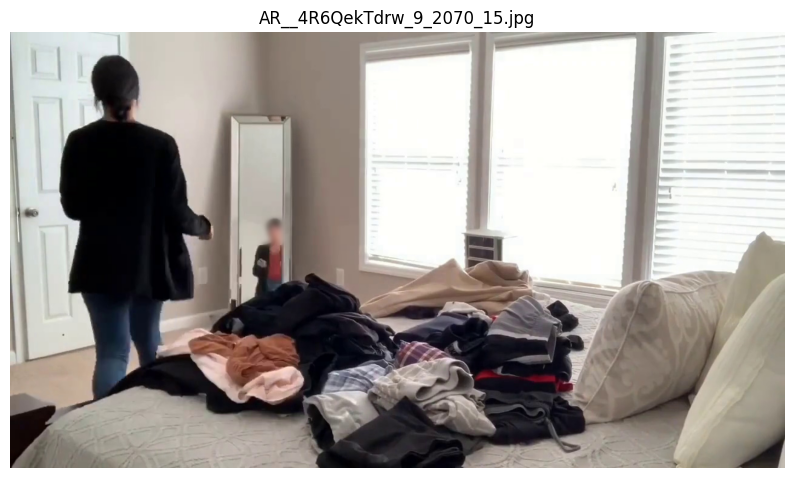

In [12]:
from PIL import Image
import matplotlib.pyplot as plt

test_image = Image.open(test_image_path)

print("Image size:", test_image.size)

plt.figure(figsize=(10, 7))
plt.imshow(test_image)
plt.axis("off")
plt.title(test_entry["image_name"])
plt.show()

# ============================================================
# SECTION 12 — GEMMA 3 VISION INFERENCE
# ============================================================

In [13]:

response = gemma_client.models.generate_content(
    model=VISION_MODEL,
    contents=[
        test_image,
        VISION_PROMPT,
    ],
    config={
        "response_mime_type": "application/json",
        "response_schema": VISION_SCHEMA,
    },
)

print(response.text)

{
  "hands": [
    {
      "handedness": "right",
      "contact_state": "no_contact",
      "primary_object": "unknown",
      "hand_object_relation": "unknown",
      "grasp_type": "unknown"
    }
  ]
}


In [14]:
# ============================================================
# SECTION 13 — SAVE RAW VISION RESULT
# ============================================================

raw_vision_response = response.text

vision_result = json.loads(raw_vision_response)

print(json.dumps(vision_result, indent=2))

{
  "hands": [
    {
      "handedness": "right",
      "contact_state": "no_contact",
      "primary_object": "unknown",
      "hand_object_relation": "unknown",
      "grasp_type": "unknown"
    }
  ]
}


# ============================================================
# SECTION 14 — VISUAL + GROUND TRUTH COMPARISON
# ============================================================

IMAGE
AR__4R6QekTdrw_9_2070_15.jpg

Image size: (1280, 720)


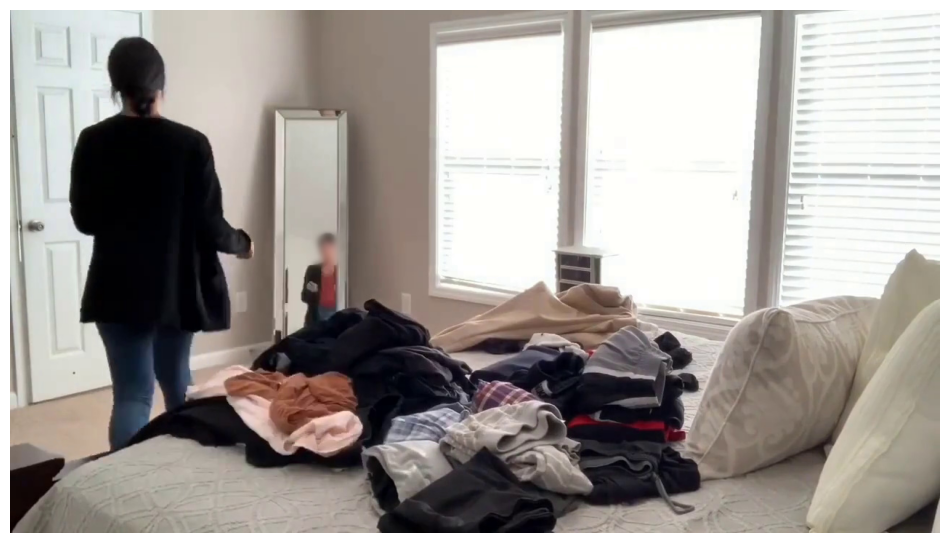


GEMINI 3.1 FLASH-LITE OUTPUT
{
  "hands": [
    {
      "handedness": "right",
      "contact_state": "no_contact",
      "primary_object": "unknown",
      "hand_object_relation": "unknown",
      "grasp_type": "unknown"
    }
  ]
}

HANDS23 GROUND-TRUTH ANNOTATION

Hand 1:
right_hand | no_contact | 310.706439, 318.336977, 336.929685, 344.655738 | None | None | None | None

Hand 2:
right_hand | inconclusive | 407.244800, 373.413600, 423.731200, 389.901600 | None | None | None | None


In [15]:


print("=" * 70)
print("IMAGE")
print("=" * 70)
print(test_entry["image_name"])

print("\nImage size:", test_image.size)

plt.figure(figsize=(12, 8))
plt.imshow(test_image)
plt.axis("off")
plt.show()

print("\n" + "=" * 70)
print("GEMINI 3.1 FLASH-LITE OUTPUT")
print("=" * 70)

print(json.dumps(vision_result, indent=2))

print("\n" + "=" * 70)
print("HANDS23 GROUND-TRUTH ANNOTATION")
print("=" * 70)

for i, annotation in enumerate(test_entry["annotations"], start=1):
    print(f"\nHand {i}:")
    print(annotation["raw"])

# ============================================================
# SECTION 15 — MULTI-IMAGE VISION TEST
# ============================================================

In [17]:
# ============================================================
# SECTION 18 — REFINED VISION TEST
# ============================================================

# ============================================================
# SECTION 15 — MULTI-IMAGE VISION TEST
# ============================================================

import time

test_entries = dataset_index[:5]


vision_test_results_v2 = []

for i, entry in enumerate(test_entries, start=1):

    image_path = Path(entry["image_path"])
    image = Image.open(image_path)

    print(f"\n[{i}/{len(test_entries)}] {entry['image_name']}")

    try:
        response = gemma_client.models.generate_content(
            model="gemini-3.1-flash-lite",
            contents=[
                image,
                VISION_PROMPT,
            ],
            config={
                "response_mime_type": "application/json",
                "response_schema": VISION_SCHEMA,
            },
        )

        result = json.loads(response.text)

        vision_test_results_v2.append({
            "image_name": entry["image_name"],
            "prediction": result,
            "ground_truth": entry["annotations"],
            "error": None
        })

        print(json.dumps(result, indent=2))

    except Exception as e:

        vision_test_results_v2.append({
            "image_name": entry["image_name"],
            "prediction": None,
            "ground_truth": entry["annotations"],
            "error": str(e)
        })

        print("ERROR:", e)

    time.sleep(1)


[1/5] AR__4R6QekTdrw_9_2070_15.jpg
{
  "hands": [
    {
      "handedness": "right",
      "contact_state": "no_contact",
      "primary_object": "unknown",
      "hand_object_relation": "unknown",
      "grasp_type": "unknown"
    }
  ]
}

[2/5] AR__4R6QekTdrw_9_2070_25.jpg
{
  "hands": [
    {
      "handedness": "unknown",
      "contact_state": "no_contact",
      "primary_object": "unknown",
      "hand_object_relation": "unknown",
      "grasp_type": "unknown"
    }
  ]
}

[3/5] AR__4R6QekTdrw_9_2070_35.jpg
{
  "hands": [
    {
      "handedness": "left",
      "contact_state": "object_contact",
      "primary_object": "hanger",
      "hand_object_relation": "held",
      "grasp_type": "unknown"
    },
    {
      "handedness": "right",
      "contact_state": "object_contact",
      "primary_object": "hanger",
      "hand_object_relation": "held",
      "grasp_type": "unknown"
    }
  ]
}

[4/5] AR__4R6QekTdrw_9_2070_45.jpg
{
  "hands": [
    {
      "handedness": "right",
     

In [18]:
# ============================================================
# SECTION 18 — COMPACT REFINED RESULTS
# ============================================================

for result in vision_test_results_v2:

    print("\n" + "=" * 70)
    print(result["image_name"])

    if result["error"]:
        print("ERROR:", result["error"])
        continue

    for hand in result["prediction"].get("hands", []):

        print(
            f"{hand['handedness']:>8} | "
            f"{hand['contact_state']:<15} | "
            f"{hand['primary_object']:<20} | "
            f"{hand['hand_object_relation']:<10} | "
            f"{hand['grasp_type']}"
        )


AR__4R6QekTdrw_9_2070_15.jpg
   right | no_contact      | unknown              | unknown    | unknown

AR__4R6QekTdrw_9_2070_25.jpg
 unknown | no_contact      | unknown              | unknown    | unknown

AR__4R6QekTdrw_9_2070_35.jpg
    left | object_contact  | hanger               | held       | unknown
   right | object_contact  | hanger               | held       | unknown

AR__4R6QekTdrw_9_2070_45.jpg
   right | object_contact  | hanger               | held       | power_grasp

AR__4R6QekTdrw_9_2070_5.jpg
ERROR: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}


# ============================================================
# SECTION 19 — CREATE VISION MODULE
# ============================================================

In [19]:


vision_files = {
    "vision_config.py": '''
VISION_MODEL = "gemini-3.1-flash-lite"
MAX_RETRIES = 3
RETRY_DELAY_SECONDS = 3
''',

    "vision_schema.py": '''
VISION_SCHEMA = {
    "type": "OBJECT",
    "properties": {
        "hands": {
            "type": "ARRAY",
            "items": {
                "type": "OBJECT",
                "properties": {
                    "handedness": {
                        "type": "STRING"
                    },
                    "contact_state": {
                        "type": "STRING"
                    },
                    "primary_object": {
                        "type": "STRING"
                    },
                    "hand_object_relation": {
                        "type": "STRING"
                    },
                    "grasp_type": {
                        "type": "STRING"
                    }
                },
                "required": [
                    "handedness",
                    "contact_state",
                    "primary_object",
                    "hand_object_relation",
                    "grasp_type"
                ]
            }
        }
    },
    "required": ["hands"]
}

VALID_HANDEDNESS = {
    "left",
    "right",
    "unknown"
}

VALID_CONTACT_STATES = {
    "no_contact",
    "object_contact",
    "inconclusive",
    "unknown"
}

VALID_RELATIONS = {
    "held",
    "touched",
    "near",
    "unknown"
}
''',

    "vision_prompt.py": '''
VISION_PROMPT = """
You are the vision perception component of a multimodal
EEG + EMG + Image + Text system.

Analyze ONLY the provided image.

For every visibly distinguishable relevant hand:

1. Determine handedness:
   left, right, or unknown.

2. Determine current contact state:
   no_contact, object_contact, inconclusive, or unknown.

3. Identify the primary object associated with the hand.
   Use a short visually supported name.
   If it cannot be identified, return unknown.

4. Determine the current hand-object relation:
   held, touched, near, or unknown.

5. Determine grasp type only when visually inferable.
   Otherwise return unknown.

IMPORTANT:
- Count only visibly distinguishable hands.
- Do not invent hidden hands.
- Do not invent objects.
- Do not use external annotations.
- Do not infer human intention.
- Do not infer temporal information from a single image.
- "held" describes the current visual state only.
- If evidence is insufficient, use unknown.
- Return one entry per relevant visible hand.
"""
''',

    "__init__.py": '''
'''
}

for filename, content in vision_files.items():
    path = VISION_CODE_DIR / filename

    with open(path, "w", encoding="utf-8") as f:
        f.write(content.strip() + "\n")

    print("Created:", path)

Created: /content/drive/MyDrive/NITT/Sem 5/PWPI/Multimodal_EEG_EMG_VLM_Project/03_Code/Vision/vision_config.py
Created: /content/drive/MyDrive/NITT/Sem 5/PWPI/Multimodal_EEG_EMG_VLM_Project/03_Code/Vision/vision_schema.py
Created: /content/drive/MyDrive/NITT/Sem 5/PWPI/Multimodal_EEG_EMG_VLM_Project/03_Code/Vision/vision_prompt.py
Created: /content/drive/MyDrive/NITT/Sem 5/PWPI/Multimodal_EEG_EMG_VLM_Project/03_Code/Vision/__init__.py


In [20]:
# ============================================================
# SECTION 20 — VISION MODEL WRAPPER
# ============================================================

vision_model_code = r'''
import json
import time

from google import genai

from .vision_config import (
    VISION_MODEL,
    MAX_RETRIES,
    RETRY_DELAY_SECONDS,
)

from .vision_schema import VISION_SCHEMA


def create_vision_client(api_key):
    """
    Create Gemini client for vision inference.
    """
    if not api_key:
        raise ValueError("Gemini API key is required.")

    return genai.Client(api_key=api_key)


def run_vision_inference(client, image, prompt):
    """
    Run vision inference with structured JSON output.

    Retries temporary API failures such as HTTP 503.
    """

    last_error = None

    for attempt in range(1, MAX_RETRIES + 1):

        try:

            response = client.models.generate_content(
                model=VISION_MODEL,
                contents=[
                    image,
                    prompt,
                ],
                config={
                    "response_mime_type": "application/json",
                    "response_schema": VISION_SCHEMA,
                },
            )

            return json.loads(response.text)

        except Exception as e:

            last_error = e

            print(
                f"Vision inference attempt "
                f"{attempt}/{MAX_RETRIES} failed: {e}"
            )

            if attempt < MAX_RETRIES:
                time.sleep(RETRY_DELAY_SECONDS)

    raise RuntimeError(
        f"Vision inference failed after "
        f"{MAX_RETRIES} attempts."
    ) from last_error
'''

with open(
    VISION_CODE_DIR / "vision_model.py",
    "w",
    encoding="utf-8"
) as f:
    f.write(vision_model_code)

print("Created:", VISION_CODE_DIR / "vision_model.py")

Created: /content/drive/MyDrive/NITT/Sem 5/PWPI/Multimodal_EEG_EMG_VLM_Project/03_Code/Vision/vision_model.py


# ============================================================
# SECTION 21 — VISION OUTPUT PARSER
# ============================================================

In [21]:


vision_parser_code = r'''
from .vision_schema import (
    VALID_HANDEDNESS,
    VALID_CONTACT_STATES,
    VALID_RELATIONS,
)


def normalize_value(value):
    if value is None:
        return "unknown"

    value = str(value).strip()

    if not value:
        return "unknown"

    return value


def parse_vision_output(raw_output):
    """
    Validate and normalize Gemma/Gemini vision output.
    """

    if not isinstance(raw_output, dict):
        raise ValueError(
            "Vision output must be a dictionary."
        )

    hands = raw_output.get("hands", [])

    if not isinstance(hands, list):
        raise ValueError(
            "Vision 'hands' field must be a list."
        )

    normalized_hands = []

    for hand in hands:

        if not isinstance(hand, dict):
            continue

        handedness = normalize_value(
            hand.get("handedness")
        ).lower()

        contact_state = normalize_value(
            hand.get("contact_state")
        ).lower()

        relation = normalize_value(
            hand.get("hand_object_relation")
        ).lower()

        primary_object = normalize_value(
            hand.get("primary_object")
        )

        grasp_type = normalize_value(
            hand.get("grasp_type")
        )

        if handedness not in VALID_HANDEDNESS:
            handedness = "unknown"

        if contact_state not in VALID_CONTACT_STATES:
            contact_state = "unknown"

        if relation not in VALID_RELATIONS:
            relation = "unknown"

        normalized_hands.append({
            "handedness": handedness,
            "contact_state": contact_state,
            "primary_object": primary_object,
            "hand_object_relation": relation,
            "grasp_type": grasp_type,
        })

    return {
        "hands": normalized_hands
    }
'''

with open(
    VISION_CODE_DIR / "vision_parser.py",
    "w",
    encoding="utf-8"
) as f:
    f.write(vision_parser_code)

print("Created:", VISION_CODE_DIR / "vision_parser.py")

Created: /content/drive/MyDrive/NITT/Sem 5/PWPI/Multimodal_EEG_EMG_VLM_Project/03_Code/Vision/vision_parser.py


In [22]:
# ============================================================
# SECTION 22 — HIGH-LEVEL VISION INFERENCE
# ============================================================

vision_inference_code = r'''
from .vision_prompt import VISION_PROMPT
from .vision_model import run_vision_inference
from .vision_parser import parse_vision_output


def infer_vision(client, image):
    """
    Complete image → structured vision pipeline.
    """

    raw_output = run_vision_inference(
        client=client,
        image=image,
        prompt=VISION_PROMPT,
    )

    parsed_output = parse_vision_output(
        raw_output
    )

    return parsed_output
'''

with open(
    VISION_CODE_DIR / "vision_inference.py",
    "w",
    encoding="utf-8"
) as f:
    f.write(vision_inference_code)

print("Created:", VISION_CODE_DIR / "vision_inference.py")

Created: /content/drive/MyDrive/NITT/Sem 5/PWPI/Multimodal_EEG_EMG_VLM_Project/03_Code/Vision/vision_inference.py


In [23]:
# ============================================================
# SECTION 23 — IMPORT VISION MODULE
# ============================================================

from Vision.vision_config import VISION_MODEL
from Vision.vision_prompt import VISION_PROMPT
from Vision.vision_schema import VISION_SCHEMA
from Vision.vision_model import (
    create_vision_client,
    run_vision_inference,
)
from Vision.vision_parser import parse_vision_output
from Vision.vision_inference import infer_vision

print("Vision module imported successfully.")
print("Vision model:", VISION_MODEL)

Vision module imported successfully.
Vision model: gemini-3.1-flash-lite


In [24]:
# ============================================================
# SECTION 24 — END-TO-END VISION TEST
# ============================================================

gemma_vision_client = create_vision_client(
    GEMINI_API_KEY
)

test_image = Image.open(
    dataset_index[2]["image_path"]
)

vision_output = infer_vision(
    client=gemma_vision_client,
    image=test_image,
)

print(json.dumps(
    vision_output,
    indent=2
))

{
  "hands": [
    {
      "handedness": "left",
      "contact_state": "object_contact",
      "primary_object": "hangers",
      "hand_object_relation": "held",
      "grasp_type": "power_grasp"
    },
    {
      "handedness": "right",
      "contact_state": "object_contact",
      "primary_object": "hangers",
      "hand_object_relation": "held",
      "grasp_type": "power_grasp"
    }
  ]
}


Section 25 — Test reusable inference on one image

In [26]:
from PIL import Image
from google.colab import userdata

from Vision.vision_model import create_vision_client
from Vision.vision_inference import infer_vision

GEMINI_API_KEY = userdata.get("API_KEY")

vision_client = create_vision_client(GEMINI_API_KEY)

test_image_path = dataset_index[2]["image_path"]

image = Image.open(test_image_path).convert("RGB")

vision_result = infer_vision(
    client=vision_client,
    image=image
)

vision_result

{'hands': [{'handedness': 'left',
   'contact_state': 'object_contact',
   'primary_object': 'hanger',
   'hand_object_relation': 'held',
   'grasp_type': 'power_grasp'},
  {'handedness': 'right',
   'contact_state': 'object_contact',
   'primary_object': 'hanger',
   'hand_object_relation': 'held',
   'grasp_type': 'power_grasp'}]}

In [31]:
import json

print(json.dumps(vision_result, indent=2))
def print_vision_result(result):
    print(f"Number of hands: {len(result.get('hands', []))}")

    for i, hand in enumerate(result.get("hands", []), start=1):
        print(f"\nHand {i}")
        print(f"  Handedness       : {hand['handedness']}")
        print(f"  Contact state    : {hand['contact_state']}")
        print(f"  Primary object   : {hand['primary_object']}")
        print(f"  Relation         : {hand['hand_object_relation']}")
        print(f"  Grasp type       : {hand['grasp_type']}")
print_vision_result(vision_result)

{
  "hands": [
    {
      "handedness": "left",
      "contact_state": "object_contact",
      "primary_object": "hanger",
      "hand_object_relation": "held",
      "grasp_type": "power_grasp"
    },
    {
      "handedness": "right",
      "contact_state": "object_contact",
      "primary_object": "hanger",
      "hand_object_relation": "held",
      "grasp_type": "power_grasp"
    }
  ]
}
Number of hands: 2

Hand 1
  Handedness       : left
  Contact state    : object_contact
  Primary object   : hanger
  Relation         : held
  Grasp type       : power_grasp

Hand 2
  Handedness       : right
  Contact state    : object_contact
  Primary object   : hanger
  Relation         : held
  Grasp type       : power_grasp


Section 27 — Run Vision on the 26-image subset

In [32]:
import time
from PIL import Image

vision_predictions = []

for i, item in enumerate(dataset_index):

    print(f"[{i+1}/{len(dataset_index)}] {item['image_name']}")

    try:
        image = Image.open(item["image_path"]).convert("RGB")

        prediction = infer_vision(
            client=vision_client,
            image=image
        )

        vision_predictions.append({
            "image_name": item["image_name"],
            "image_path": item["image_path"],
            "prediction": prediction,
            "status": "success"
        })

        print("  ✓ success")

    except Exception as e:

        print(f"  ✗ failed: {e}")

        vision_predictions.append({
            "image_name": item["image_name"],
            "image_path": item["image_path"],
            "prediction": None,
            "status": "failed",
            "error": str(e)
        })

    time.sleep(1)

[1/26] AR__4R6QekTdrw_9_2070_15.jpg
  ✓ success
[2/26] AR__4R6QekTdrw_9_2070_25.jpg
  ✓ success
[3/26] AR__4R6QekTdrw_9_2070_35.jpg
  ✓ success
[4/26] AR__4R6QekTdrw_9_2070_45.jpg
  ✓ success
[5/26] AR__4R6QekTdrw_9_2070_5.jpg
  ✓ success
[6/26] AR__4R6QekTdrw_9_2070_55.jpg
  ✓ success
[7/26] AR__4R6QekTdrw_9_2070_65.jpg
  ✓ success
[8/26] AR__4R6QekTdrw_9_2070_75.jpg
  ✓ success
[9/26] AR__4R6QekTdrw_9_2070_85.jpg
  ✓ success
[10/26] AR__4R6QekTdrw_9_990_15.jpg
  ✓ success
[11/26] AR__4R6QekTdrw_9_990_35.jpg
  ✓ success
[12/26] AR__4R6QekTdrw_9_990_45.jpg
  ✓ success
[13/26] AR__4R6QekTdrw_9_990_5.jpg
  ✓ success
[14/26] AR__4R6QekTdrw_9_990_55.jpg
  ✓ success
[15/26] AR__4R6QekTdrw_9_990_65.jpg
  ✓ success
[16/26] AR__4R6QekTdrw_9_990_85.jpg
  ✓ success
[17/26] AR__5wD2rAL280_18_0_15.jpg
  ✓ success
[18/26] AR__5wD2rAL280_18_0_25.jpg
  ✓ success
[19/26] AR__5wD2rAL280_18_0_35.jpg
  ✓ success
[20/26] AR__5wD2rAL280_18_0_45.jpg
  ✓ success
[21/26] AR__5wD2rAL280_18_0_5.jpg
  ✓ success


Check success/Failure

In [33]:
success_count = sum(
    x["status"] == "success"
    for x in vision_predictions
)

failed_count = sum(
    x["status"] == "failed"
    for x in vision_predictions
)

print("Total :", len(vision_predictions))
print("Success:", success_count)
print("Failed :", failed_count)

Total : 26
Success: 26
Failed : 0


Section 29 — Save raw Vision predictions

In [34]:
RESULTS_DIR = PROJECT_ROOT / "04_Results" / "Vision"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(RESULTS_DIR)
import json

VISION_RESULTS_PATH = RESULTS_DIR / "hands23_vision_predictions.json"

with open(VISION_RESULTS_PATH, "w") as f:
    json.dump(vision_predictions, f, indent=2)

print(f"Saved to: {VISION_RESULTS_PATH}")

/content/drive/MyDrive/NITT/Sem 5/PWPI/Multimodal_EEG_EMG_VLM_Project/04_Results/Vision
Saved to: /content/drive/MyDrive/NITT/Sem 5/PWPI/Multimodal_EEG_EMG_VLM_Project/04_Results/Vision/hands23_vision_predictions.json


In [35]:
with open(VISION_RESULTS_PATH, "r") as f:
    loaded_predictions = json.load(f)

print(len(loaded_predictions))
print(loaded_predictions[0])

26
{'image_name': 'AR__4R6QekTdrw_9_2070_15.jpg', 'image_path': '/content/drive/MyDrive/NITT/Sem 5/PWPI/Multimodal_EEG_EMG_VLM_Project/01_Data/Image/hands23/jpg/AR__4R6QekTdrw_9_2070_15.jpg', 'prediction': {'hands': [{'handedness': 'right', 'contact_state': 'no_contact', 'primary_object': 'unknown', 'hand_object_relation': 'unknown', 'grasp_type': 'unknown'}]}, 'status': 'success'}


# Section 31 — Build Ground Truth + Prediction inspection table

In [36]:
import pandas as pd

inspection_rows = []

for pred_item in loaded_predictions:

    image_name = pred_item["image_name"]

    gt_item = next(
        x for x in dataset_index
        if x["image_name"] == image_name
    )

    prediction = pred_item.get("prediction")

    if prediction is None:
        inspection_rows.append({
            "image": image_name,
            "gt_hands": gt_item["num_hands"],
            "pred_hands": None,
            "status": pred_item["status"]
        })
        continue

    inspection_rows.append({
        "image": image_name,
        "gt_hands": gt_item["num_hands"],
        "pred_hands": len(prediction.get("hands", [])),
        "status": pred_item["status"]
    })

inspection_df = pd.DataFrame(inspection_rows)

inspection_df

,image,gt_hands,pred_hands,status
0,AR__4R6QekTdrw_9_2070_15.jpg,2,1,success
1,AR__4R6QekTdrw_9_2070_25.jpg,0,2,success
2,AR__4R6QekTdrw_9_2070_35.jpg,2,2,success
3,AR__4R6QekTdrw_9_2070_45.jpg,1,2,success
4,AR__4R6QekTdrw_9_2070_5.jpg,2,2,success
5,AR__4R6QekTdrw_9_2070_55.jpg,1,2,success
6,AR__4R6QekTdrw_9_2070_65.jpg,2,2,success
7,AR__4R6QekTdrw_9_2070_75.jpg,1,1,success
8,AR__4R6QekTdrw_9_2070_85.jpg,1,2,success
9,AR__4R6QekTdrw_9_990_15.jpg,2,2,success


# Section 32 — Inspect individual Ground Truth vs Gemini

In [39]:
def show_gt_and_prediction(index):

    item = dataset_index[index]

    print("=" * 80)
    print("IMAGE:", item["image_name"])

    print("\nGROUND TRUTH")

    for i, ann in enumerate(item["annotations"], start=1):
        print(f"\nHand {i}:")
        print("  Annotation dictionary:")
        print(ann)

    pred_item = next(
        x for x in loaded_predictions
        if x["image_name"] == item["image_name"]
    )

    print("\nVISION PREDICTION")

    if pred_item["prediction"] is None:
        print("Prediction failed.")
    else:
        print_vision_result(pred_item["prediction"])
show_gt_and_prediction(3)
show_gt_and_prediction(4)
show_gt_and_prediction(5)

IMAGE: AR__4R6QekTdrw_9_2070_45.jpg

GROUND TRUTH

Hand 1:
  Annotation dictionary:
{'raw': 'right_hand | object_contact | 763.591470, 303.843594, 823.294509, 352.212978 | 678.304130, 293.279989, 888.798831, 442.574382 | neither_,_held | None | None', 'fields': ['right_hand', 'object_contact', '763.591470, 303.843594, 823.294509, 352.212978', '678.304130, 293.279989, 888.798831, 442.574382', 'neither_,_held', 'None', 'None'], 'num_fields': 7}

VISION PREDICTION
Number of hands: 2

Hand 1
  Handedness       : right
  Contact state    : object_contact
  Primary object   : clothing hanger
  Relation         : held
  Grasp type       : pinch

Hand 2
  Handedness       : left
  Contact state    : object_contact
  Primary object   : clothing hanger
  Relation         : held
  Grasp type       : pinch
IMAGE: AR__4R6QekTdrw_9_2070_5.jpg

GROUND TRUTH

Hand 1:
  Annotation dictionary:
{'raw': 'right_hand | object_contact | 330.537262, 408.077145, 417.733990, 481.182266 | 311.779152, 408.233958,

In [40]:
# Section 33 — Create an annotation normalization layer

# Section 33 — Create an annotation normalization layer

In [41]:
ground_truth_code = r'''
def normalize_hands23_contact(value):
    value = str(value).strip().lower()

    mapping = {
        "no_contact": "no_contact",
        "object_contact": "object_contact",
        "inconclusive": "inconclusive",
        "none": "unknown",
    }

    return mapping.get(value, "unknown")


def normalize_hands23_handedness(value):
    value = str(value).strip().lower()

    if value in {"left_hand", "left"}:
        return "left"

    if value in {"right_hand", "right"}:
        return "right"

    return "unknown"


def normalize_hands23_grasp(value):
    value = str(value).strip()

    if value == "Pow-Pris":
        return "power_grasp"

    return "unknown"
'''

with open(VISION_CODE_DIR / "ground_truth.py", "w") as f:
    f.write(ground_truth_code)

print("Created ground_truth.py")

Created ground_truth.py


# Section 35 — Test Vision → Prompt context

In [42]:
import importlib
import Prompt.context as prompt_context

importlib.reload(prompt_context)

from Prompt.context import build_vision_context

vision_context = build_vision_context(
    hands=vision_result["hands"]
)

vision_context

{'hands': [{'handedness': 'left',
   'contact_state': 'object_contact',
   'primary_object': 'hanger',
   'hand_object_relation': 'held',
   'grasp_type': 'power_grasp'},
  {'handedness': 'right',
   'contact_state': 'object_contact',
   'primary_object': 'hanger',
   'hand_object_relation': 'held',
   'grasp_type': 'power_grasp'}]}

# Section 36 — Test complete multimodal context

In [43]:
from Prompt.context import build_multimodal_context

test_eeg_output = {
    "gesture": "large_diameter_grasp",
    "confidence": 0.91
}

test_emg_output = {
    "gesture": "large_diameter_grasp",
    "confidence": 0.88
}

task_instruction = "Pick up the cup."

multimodal_context = build_multimodal_context(
    task_instruction=task_instruction,
    eeg_output=test_eeg_output,
    emg_output=test_emg_output,
    vision_output=vision_context
)

import json

print(json.dumps(multimodal_context, indent=2))

{
  "task": {
    "instruction": "Pick up the cup."
  },
  "eeg": {
    "gesture": "large_diameter_grasp",
    "confidence": 0.91
  },
  "emg": {
    "gesture": "large_diameter_grasp",
    "confidence": 0.88
  },
  "vision": {
    "hands": [
      {
        "handedness": "left",
        "contact_state": "object_contact",
        "primary_object": "hanger",
        "hand_object_relation": "held",
        "grasp_type": "power_grasp"
      },
      {
        "handedness": "right",
        "contact_state": "object_contact",
        "primary_object": "hanger",
        "hand_object_relation": "held",
        "grasp_type": "power_grasp"
      }
    ]
  }
}


# Section 37 — Build the final Vision inference API

In [46]:
# Section 37 — Test complete Vision inference API

import sys
import importlib

# Make Vision package importable
if str(VISION_CODE_DIR.parent) not in sys.path:
    sys.path.insert(0, str(VISION_CODE_DIR.parent))

import Vision.vision_inference as vision_inference
importlib.reload(vision_inference)

from Vision.vision_inference import infer_vision

from PIL import Image

sample_item = dataset_index[2]

sample_image = Image.open(
    sample_item["image_path"]
).convert("RGB")

final_vision_output = infer_vision(
    client=vision_client,
    image=sample_image
)

print_vision_result(final_vision_output)

Number of hands: 2

Hand 1
  Handedness       : left
  Contact state    : object_contact
  Primary object   : hanger
  Relation         : held
  Grasp type       : power_grasp

Hand 2
  Handedness       : right
  Contact state    : object_contact
  Primary object   : hanger
  Relation         : held
  Grasp type       : power_grasp
